# ***Bulid the Multi Layer Perceotron***

In [1]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import seaborn as sns

# Load tips dataset
tips = sns.load_dataset('tips')

# Preprocessing
# Converting categorical variables to dummy variables
tips = pd.get_dummies(tips, drop_first=True)

In [2]:
# Selecting features and target (predicting 'tip' based on other features)
X = tips.drop('tip', axis=1)
y = tips['tip']

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)

# Standardizing the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [3]:
# Building the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu',
                          input_shape=(X_train.shape[1],)),  # Input layer

    tf.keras.layers.Dense(32, activation='relu'),  # Hidden layer

    tf.keras.layers.Dense(1)  # Output layer for regression
])

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error',metrics=['mae'])

# Training the model
model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=1)

# Evaluating the model (using Mean Squared Error)
loss = model.evaluate(X_test, y_test, verbose=0)
print('Mean Squared Error: ', loss[0])

c:\Users\AHSAN GHANI\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 12.3877 - mae: 3.2124
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.8032 - mae: 2.8109
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.8674 - mae: 2.4589
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.2280 - mae: 2.1132
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 4.7836 - mae: 1.7820
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 3.6245 - mae: 1.4862
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2.6436 - mae: 1.2419
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 2.0102 - mae: 1.0742
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.6270 - mae: 0.9723 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.4527 - mae: 0.9177 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.3974 - mae: 0.9036 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.3517 - mae: 0.8885
Epoch 13/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/st

c:\Users\AHSAN GHANI\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - loss: 1.1915


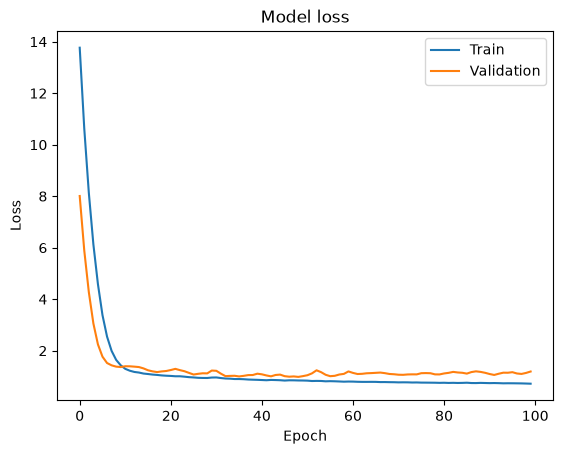

1.1915361881256104

In [4]:
# Building the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),  # Hidden layer
    tf.keras.layers.Dense(1)  # Output layer for regression
])

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')
# train the model and plot the training and testing loss and accuracy at each epoch
history = model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0,
                    validation_data=(X_test, y_test))

# Evaluating the model (using Mean Squared Error)
loss = model.evaluate(X_test, y_test, verbose=1)

# Plotting the training and testing loss
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()
loss

# **Early Stoping Epoch**

c:\Users\AHSAN GHANI\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


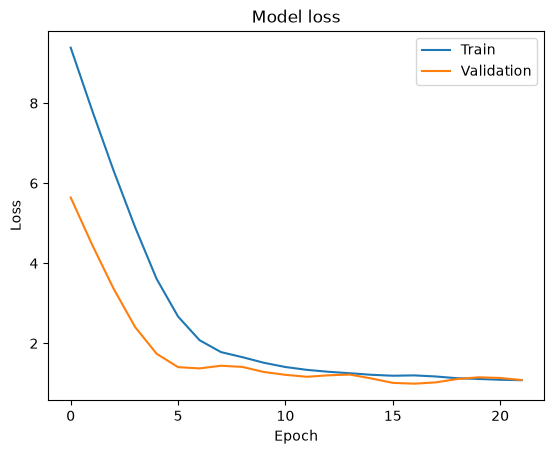

In [5]:
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

# Building the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),  # Input layer
    tf.keras.layers.Dense(32, activation='relu'),  # Hidden layer
    tf.keras.layers.Dense(1)  # Output layer for regression
])


# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Define the callback function
early_stopping = EarlyStopping(patience=5)

# Train the model with the callback function
history = model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0,
                    validation_data=(X_test, y_test),
                    callbacks=[early_stopping])

# Evaluating the model (using Mean Squared Error)
loss = model.evaluate(X_test, y_test, verbose=0)
loss
# Plotting the training and testing loss
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step


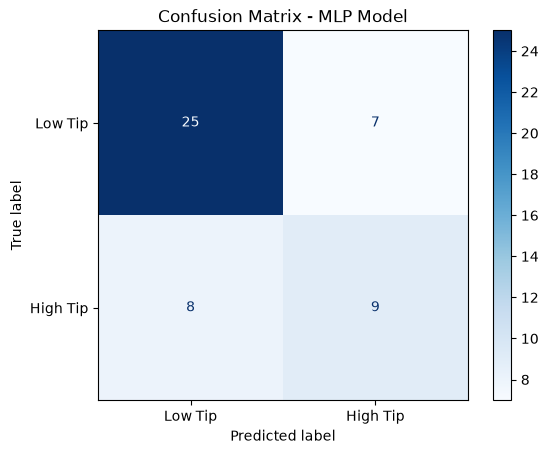

In [6]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Make predictions
y_pred = model.predict(X_test).flatten()

# Convert regression values into two classes
threshold = y_train.median()

y_test_class = (np.array(y_test) >= threshold).astype(int)
y_pred_class = (y_pred >= threshold).astype(int)

# Create confusion matrix
cm = confusion_matrix(y_test_class, y_pred_class)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Tip", "High Tip"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - MLP Model")
plt.show()


# **Parameter Tuning**

In [7]:

import tensorflow as tf
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Different parameter combinations
parameters = [
    (32, 16, 0.001, 16),
    (32, 16, 0.0005, 32),
    (64, 32, 0.001, 16),
    (64, 32, 0.0005, 32),
    (128, 64, 0.001, 16),
    (128, 64, 0.0005, 32)
]

results = []

for units1, units2, lr, batch in parameters:

    # Build model
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(units1, activation='relu'),
        Dense(units2, activation='relu'),
        Dense(1)
    ])

    # Compile model
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='mean_squared_error',
        metrics=['mae']
    )

    # Early stopping
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Train model
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_test, y_test),
        epochs=100,
        batch_size=batch,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate model
    loss, mae = model.evaluate(X_test, y_test, verbose=0)

    results.append({
        'Hidden Layers': f'{units1}, {units2}',
        'Learning Rate': lr,
        'Batch Size': batch,
        'MSE': loss,
        'MAE': mae
    })

# Show results
results_df = pd.DataFrame(results)

print(results_df)

# Best parameter combination
best_result = results_df.loc[results_df['MSE'].idxmin()]

print("\nBest Parameters:")
print(best_result)


  Hidden Layers  Learning Rate  Batch Size       MSE       MAE
0        32, 16         0.0010          16  1.056224  0.838959
1        32, 16         0.0005          32  0.777980  0.724441
2        64, 32         0.0010          16  0.971855  0.838457
3        64, 32         0.0005          32  1.183170  0.819279
4       128, 64         0.0010          16  0.936740  0.800340
5       128, 64         0.0005          32  1.055446  0.859691

Best Parameters:
Hidden Layers      32, 16
Learning Rate      0.0005
Batch Size             32
MSE               0.77798
MAE              0.724441
Name: 1, dtype: object
